# Lab: diagnosticando e selecionando modelos para o preço de casas na Califórnia

Notebook de aula da página: https://insper.github.io/ML/pt/2026.2/classes/model-selection/

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

## Passo 1 — carregar e olhar

**Preveja.** O alvo é o valor mediano das casas de cada distrito. Você espera uma distribuição simétrica ou com cauda longa? E se o censo tivesse um teto para os valores altos, o que isso faria com o erro de qualquer modelo?

In [1]:
import numpy as np
import pandas as pd

url = 'https://raw.githubusercontent.com/hsandmann/biblio/refs/heads/main/ml/aula02/housing.csv'
df = pd.read_csv(url)
print(df.shape)
print(df.isna().sum()[lambda s: s > 0])
print(df['median_house_value'].describe().round(0))
print('districts at the 500,001 cap:', (df['median_house_value'] >= 500_001).sum())

(20640, 10)
total_bedrooms    207
dtype: int64
count     20640.0
mean     206856.0
std      115396.0
min       14999.0
25%      119600.0
50%      179700.0
75%      264725.0
max      500001.0
Name: median_house_value, dtype: float64
districts at the 500,001 cap: 965


**Resposta.** Cauda longa à direita: a média (US\$ 206.856) fica acima da mediana (US\$ 179.700) e o máximo, US\$ 500.001, está bem longe do 3º quartil (US\$ 264.725). Os 965 distritos no teto têm um valor verdadeiro desconhecido (algo acima de US\$ 500.000), então todo modelo é cobrado contra um número que não é o preço real e o erro fica inflado, sobretudo para modelos que não conseguem se achatar num teto, como os lineares.

## Passo 2 — trancar o conjunto de teste, um `cv` para tudo

**Preveja.** O baseline prevê o mesmo preço para todo distrito. A raiz do erro quadrático médio (RMSE, do inglês *root mean squared error*) dele deve ficar perto de qual estatística dos preços que você viu no passo 1?

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

X = df.drop(columns='median_house_value')
y = df['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

counts = ['total_rooms', 'total_bedrooms', 'population', 'households']      # assimétricas: log nelas
others = ['longitude', 'latitude', 'housing_median_age', 'median_income']
pre = ColumnTransformer([
    ('counts', make_pipeline(SimpleImputer(strategy='median'), FunctionTransformer(np.log1p),
                             StandardScaler()), counts),
    ('others', StandardScaler(), others),
    ('ocean', OneHotEncoder(handle_unknown='ignore'), ['ocean_proximity']),
])
cv = KFold(n_splits=5, shuffle=True, random_state=42)                      # um cv para tudo


def rmse(model):
    """RMSE médio de treino e de validação nos 5 folds e o desvio-padrão da validação entre folds."""
    r = cross_validate(model, X_train, y_train, cv=cv, return_train_score=True,
                       scoring='neg_root_mean_squared_error')
    return abs(r['train_score'].mean()), abs(r['test_score'].mean()), r['test_score'].std()


print(X_train.shape, X_test.shape)
print('dummy (predicts the mean): train %.0f · validation %.0f ± %.0f' % rmse(DummyRegressor()))

(16512, 9) (4128, 9)
dummy (predicts the mean): train 114784 · validation 114793 ± 1401


**Resposta.** Do desvio-padrão dos preços: prever a média para todos dá RMSE de validação de US\$ 114.793 ± 1.401, praticamente o desvio-padrão de US\$ 115.396 do passo 1. É a régua contra a qual todo modelo deve ser lido.

## Passo 3 — três famílias, um primeiro diagnóstico

**Preveja.** Uma árvore sem limite de profundidade e uma regressão linear: qual delas vai ter o menor erro de treino? E a maior distância entre treino e validação?

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

candidates = {
    'linear': make_pipeline(pre, LinearRegression()),
    'k-NN (k=5)': make_pipeline(pre, KNeighborsRegressor()),
    'tree (no limits)': make_pipeline(pre, DecisionTreeRegressor(random_state=42)),
}
print(f"{'':17s} {'train':>7s} {'valid':>7s} {'gap':>7s}")
for name, model in candidates.items():
    tr, va, sd = rmse(model)
    print(f"{name:17s} {tr:7.0f} {va:7.0f} {va - tr:7.0f}")

                    train   valid     gap
linear              66369   66460      91


k-NN (k=5)          48898   59967   11069


tree (no limits)        0   67266   67266


**Resposta.** A árvore sem limites tem o menor erro de treino (0) e também a maior distância (US\$ 67.266): ela memorizou os distritos de treino. A regressão linear erra quase o mesmo nos dois (66.369 e 66.460, distância de US\$ 91), a assinatura do viés; o k-NN fica no meio (distância de 11.069) e tem a melhor validação, 59.967.

**Simulação: a variância, vista de perto.** A distância entre treino e validação é um sintoma; a variância é a causa: o quanto o modelo muda quando a amostra muda. Meça isso diretamente. Divida `X_train` em três partes disjuntas, A, B e C; treine cada família duas vezes, uma em A e outra em B, e compare as previsões das duas versões nos mesmos distritos de C. Qual família muda mais de uma amostra para outra?

In [4]:
from sklearn.base import clone

parts = np.array_split(np.random.default_rng(42).permutation(len(X_train)), 3)   # A, B e C disjuntas
(XA, yA), (XB, yB), (XC, yC) = [(X_train.iloc[p], y_train.iloc[p]) for p in parts]
print(f"three disjoint parts of {len(XA)}, {len(XB)} and {len(XC)} districts")
for name, model in candidates.items():
    pa = clone(model).fit(XA, yA).predict(XC)          # versão treinada em A
    pb = clone(model).fit(XB, yB).predict(XC)          # versão treinada em B
    err = np.sqrt(np.mean((yC - pa) ** 2))
    shift = np.sqrt(np.mean((pa - pb) ** 2))           # RMS da diferença entre as duas versões
    print(f"{name:17s} RMSE on C {err:6.0f} · A and B versions differ by {shift:6.0f}")

three disjoint parts of 5504, 5504 and 5504 districts
linear            RMSE on C  68526 · A and B versions differ by   3339


k-NN (k=5)        RMSE on C  64542 · A and B versions differ by  38213


tree (no limits)  RMSE on C  73495 · A and B versions differ by  79278


**Leitura.** Nos mesmos 5.504 distritos de C, as versões A e B da regressão linear discordam em só US\$ 3.339; as do k-NN, em US\$ 38.213; as da árvore sem limites, em US\$ 79.278, mais do que o próprio erro dela em C (US\$ 73.495), porque cada árvore copiou o ruído da sua parte. A árvore é a família que mais muda de uma amostra para outra e a linear a que menos muda: é a variância medida diretamente, sem conhecer a verdade. Com um terço dos dados, a árvore e o k-NN também erram mais que no passo 3 (73.495 e 64.542, contra 67.266 e 59.967).

## Passo 4 — curvas de aprendizado: mais dados ajudariam?

**Preveja.** O modelo linear já erra quase o mesmo no treino e na validação. Dobrar o número de distritos vai baixar o erro de validação dele? E o da árvore sem limites?

linear            n        264    660   1320   2641   5283   9246  13209
                  train   59.2   64.4   66.2   66.4   65.9   66.5   66.4
                  valid   67.8   67.6   67.0   66.8   66.5   66.5   66.5


k-NN (k=5)        n        264    660   1320   2641   5283   9246  13209
                  train   59.0   56.5   54.8   52.5   50.8   50.1   48.9
                  valid   78.0   72.0   69.3   65.8   62.9   61.3   60.0


tree (no limits)  n        264    660   1320   2641   5283   9246  13209
                  train    0.0    0.0    0.0    0.0    0.0    0.0    0.0
                  valid   91.5   85.6   83.9   77.5   72.7   71.8   67.3


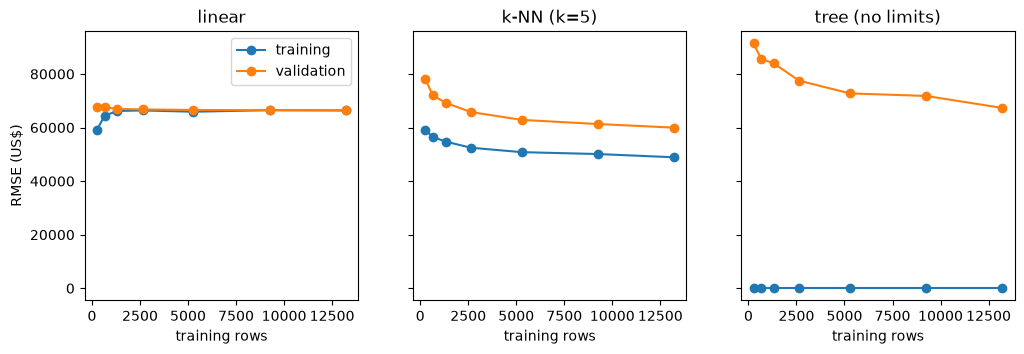

In [5]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

fractions = [0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, (name, model) in zip(axes, candidates.items()):
    sizes, train, val = learning_curve(model, X_train, y_train, train_sizes=fractions, cv=cv,
                                       scoring='neg_root_mean_squared_error')
    train, val = np.abs(train.mean(axis=1)), np.abs(val.mean(axis=1))
    print(f"{name:17s} n     " + ' '.join(f"{n:6d}" for n in sizes))
    print(f"{'':17s} train " + ' '.join(f"{v / 1000:6.1f}" for v in train))
    print(f"{'':17s} valid " + ' '.join(f"{v / 1000:6.1f}" for v in val))
    ax.plot(sizes, train, 'o-', label='training')
    ax.plot(sizes, val, 'o-', label='validation')
    ax.set_title(name)
    ax.set_xlabel('training rows')
axes[0].set_ylabel('RMSE (US$)')
axes[0].legend()
plt.show()

**Resposta.** Para o linear, não: treino e validação já se encontram com 2.641 linhas (66,4 e 66,8 mil) e a validação termina em 66,5 mil, parada; o limite é o que um hiperplano consegue representar. Para a árvore, sim, devagar: a validação ainda cai na borda direita (71,8 → 67,3 mil nas últimas 4.000 linhas), mas o treino continua em 0 e a distância não fecha.

## Passo 5 — curvas de validação: tratar a variância

**Preveja.** Exigir mais distritos em cada folha da árvore vai aumentar ou diminuir o erro de treino? E o de validação: anda sempre na mesma direção ou primeiro numa e depois na outra?

In [6]:
from sklearn.model_selection import validation_curve

knobs = {'tree': (candidates['tree (no limits)'], 'decisiontreeregressor__min_samples_leaf',
                  [1, 2, 5, 10, 20, 50, 100]),
         'k-NN': (candidates['k-NN (k=5)'], 'kneighborsregressor__n_neighbors', [1, 3, 5, 10, 20, 50])}
for name, (model, param, values) in knobs.items():
    train, val = validation_curve(model, X_train, y_train, param_name=param, param_range=values,
                                  cv=cv, scoring='neg_root_mean_squared_error')
    print(f"{name}: {param.split('__')[1]}")
    for v, tr, va in zip(values, np.abs(train.mean(axis=1)), np.abs(val.mean(axis=1))):
        print(f"  {v:4d}   train {tr:6.0f}   valid {va:6.0f}   gap {va - tr:6.0f}")

tree: min_samples_leaf
     1   train      0   valid  67266   gap  67266
     2   train  18723   valid  64812   gap  46089
     5   train  34461   valid  60469   gap  26008
    10   train  43023   valid  57796   gap  14773
    20   train  49663   valid  58079   gap   8415
    50   train  56655   valid  59891   gap   3236
   100   train  61413   valid  63505   gap   2092


k-NN: n_neighbors
     1   train      0   valid  73873   gap  73873
     3   train  43627   valid  61904   gap  18277
     5   train  48898   valid  59967   gap  11069
    10   train  53606   valid  59182   gap   5576
    20   train  57036   valid  59931   gap   2895
    50   train  61204   valid  62371   gap   1168


**Resposta.** O erro de treino sobe sempre (0 com 1 distrito por folha, 61.413 com 100). A validação não anda numa só direção: cai de 67.266 até o fundo em `min_samples_leaf = 10` (57.796) e depois volta a subir até 63.505 com 100, a forma de U; o k-NN mostra o mesmo U, com fundo em k = 10 (59.182).

## Passo 6 — tratar o viés do modelo linear

**Preveja.** Acrescentar ao modelo linear os quadrados e os produtos dos atributos deve baixar o erro de treino, o de validação ou os dois? O que pode dar errado com termos cúbicos?

In [7]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures

print('degree   alpha    train    valid  ± std')
for degree, alpha in [(1, 1), (2, 1), (3, 0.1), (3, 10), (3, 100)]:
    model = make_pipeline(pre, PolynomialFeatures(degree), StandardScaler(), Ridge(alpha=alpha))
    tr, va, sd = rmse(model)
    print(f"{degree:6d} {alpha:7g} {tr:8.0f} {va:8.0f} {sd:6.0f}")

degree   alpha    train    valid  ± std


     1       1    66369    66460   1597


     2       1    58649    59741   1823


     3     0.1    52092    63828   7751


     3      10    53038    57510   2955


     3     100    54582    57473   2381


**Resposta.** Os dois: o grau 2 baixa o treino de 66.369 para 58.649 e a validação de 66.460 para 59.741. Com termos cúbicos e penalidade fraca (`alpha = 0.1`), o modelo passa para o lado da variância: validação 63.828 e desvio entre folds de 7.751, quatro vezes o do grau 2; com `alpha = 100`, o grau 3 dá a melhor validação, 57.473 ± 2.381.

**Simulação: o `alpha` como botão contínuo.** O passo 6 testou três valores de `alpha` para o grau 3. Varra de 0,01 a 1.000.000 (oito ordens de grandeza) e acompanhe o treino, a validação, a distância entre eles e o desvio entre folds. Em qual ponta o modelo fica do lado da variância e em qual do lado do viés?

In [8]:
print('alpha      train    valid    gap  ± std')
for alpha in [0.01, 0.1, 1, 10, 100, 1e3, 1e4, 1e5, 1e6]:
    tr, va, sd = rmse(make_pipeline(pre, PolynomialFeatures(3), StandardScaler(), Ridge(alpha=alpha)))
    print(f"{alpha:<8g} {tr:7.0f} {va:8.0f} {va - tr:6.0f} {sd:6.0f}")

alpha      train    valid    gap  ± std


0.01       51931    66098  14167   8694


0.1        52092    63828  11735   7751


1          52426    60366   7940   5378


10         53038    57510   4471   2955


100        54582    57473   2890   2381


1000       58403    60047   1644   1859


10000      66352    66926    574   1330


100000     83725    83961    236   1267


1e+06     106790   106832     42   1318


**Leitura.** A distância cai de forma monótona, de 14.167 com `alpha = 0.01` para 42 com `alpha = 1e6`, e o desvio entre folds, de 8.694 para cerca de 1.300. A ponta de `alpha` pequeno é o lado da variância (treino 51.931, validação 66.098, folds instáveis); a de `alpha` grande é o lado do viés (treino e validação se encontram em cerca de US\$ 106.800, perto dos 114.793 do baseline). O fundo do U é um platô entre `alpha = 10` e `alpha = 100` (57.510 e 57.473), com o mesmo grau e os mesmos atributos.

**Para fechar a parte fundamental.** Em uma frase cada: (1) o que a distância entre o erro de treino e o de validação mede e o que ela não mede? (2) Por que mais distritos não ajudariam o modelo linear do passo 4? (3) Que botão você giraria, e para que lado, para tirar a árvore do lado da variância?

**Resposta.**

(1) A distância mede o quanto o modelo se ajustou especificamente às linhas de treino (o sintoma da variância), mas não mede o viés: o linear tem distância de US\$ 91 e ainda erra US\$ 66.460.

(2) Porque as curvas de treino e de validação do linear já se encontraram em cerca de 66,5 mil com 2.641 linhas: o que falta é flexibilidade do modelo, não dados.

(3) Aumentaria o `min_samples_leaf` (de 1 para cerca de 10), o que levou a validação da árvore de 67.266 para 57.796.

## Sua vez (fundamental)

Para casa:

1. **Mais pontos.** Rode de novo a `bias_variance` da seção 2 para polinômios com `n=100` em vez de 30. Qual grau é o melhor agora e o que aconteceu com a variância do grau 12? Relacione a resposta com as curvas de aprendizado.
2. **Mais ruído.** Rode com `sigma=0.6`. O melhor grau se move para modelos mais simples ou mais complexos? Explique com os três termos da decomposição.
3. **Atributos contra o viés.** Acrescente três razões ao `X` antes da divisão: cômodos por domicílio, quartos por cômodo e pessoas por domicílio (elas exigem uma pequena mudança em `counts`/`others`). Rode o passo 6 de novo. O platô do modelo de grau 1 se move? Por mais de um desvio-padrão entre folds?

## Passo 7 — uma busca sobre as cinco famílias

**Preveja.** Uma única busca põe Ridge, k-NN, árvore, uma random forest e um gradient boosting lado a lado. Você espera que o vencedor supere a melhor configuração de cada outra família por mais ou por menos que a oscilação da diferença entre eles de um fold para outro? E o segundo colocado da sua própria família?

In [9]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

pipe = Pipeline([('pre', pre), ('poly', PolynomialFeatures()), ('scale', StandardScaler()),
                 ('model', Ridge())])
skip = {'poly': ['passthrough'], 'scale': ['passthrough']}      # etapas que a família não usa
param_grid = [
    {'model': [Ridge()], 'poly__degree': [1, 2, 3], 'model__alpha': [1, 10, 100, 1000]},
    {'model': [KNeighborsRegressor()], **skip,
     'model__n_neighbors': [5, 10, 20], 'model__weights': ['uniform', 'distance']},
    {'model': [DecisionTreeRegressor(random_state=42)], **skip, 'model__min_samples_leaf': [5, 10, 20, 40]},
    {'model': [RandomForestRegressor(n_estimators=100, random_state=42)], **skip,
     'model__max_features': [0.33, 1.0], 'model__min_samples_leaf': [1, 5]},
    {'model': [HistGradientBoostingRegressor(max_iter=500, early_stopping=True, random_state=42)], **skip,
     'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [15, 31]},
]
search = GridSearchCV(pipe, param_grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
search.fit(X_train, y_train)


def describe(params):
    name = type(params['model']).__name__
    knobs = ', '.join(f"{k.split('__')[-1]}={v}" for k, v in params.items() if k != 'model'
                      and v != 'passthrough')
    return f"{name}({knobs})"


res = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
print(len(res), 'configurations ·', len(res) * cv.get_n_splits(), 'fits')
for _, row in res.iloc[[0, 1, 2, 3, 4, 8, 10, 12]].iterrows():
    print(f"{row['rank_test_score']:2d}  {abs(row['mean_test_score']):6.0f} ± {row['std_test_score']:5.0f}"
          f"  {describe(row['params'])}")

30 configurations · 150 fits
 1   46644 ±  1311  HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=31)
 2   46707 ±  1079  HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=31)
 3   47436 ±  1034  HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=15)
 4   47620 ±  1130  HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=15)
 5   49025 ±  1406  RandomForestRegressor(max_features=0.33, min_samples_leaf=1)
 9   57473 ±  2381  Ridge(alpha=100, degree=3)
11   57796 ±  1534  DecisionTreeRegressor(min_samples_leaf=10)
13   58517 ±  1084  KNeighborsRegressor(n_neighbors=10, weights=distance)


**Resposta.** Contra as outras famílias, por mais: o boosting vencedor (46.644 ± 1.311) fica US\$ 2.381 à frente da melhor floresta (49.025) e mais de US\$ 10.000 à frente do melhor Ridge (57.473), diferenças que a simulação abaixo mostra serem maiores que a oscilação fold a fold. Contra o segundo colocado da própria família (46.707), por bem menos: US\$ 63, muito abaixo do desvio-padrão entre folds, ou seja, um empate.

**Simulação: as duas mensagens, fold a fold.** Confirme as duas com os números de cada fold: o `cv_results_` guarda a nota de cada configuração em cada um dos cinco folds (`split0_test_score`, …). Ponha o vencedor ao lado do segundo colocado, da melhor floresta e do melhor Ridge. Em quantos folds o vencedor fica à frente de cada um e por quanto?

In [10]:
res7 = pd.DataFrame(search.cv_results_)
family = [type(p['model']).__name__ for p in res7['params']]
best_of = lambda name: res7[[f == name for f in family]]['mean_test_score'].idxmax()
rows = {'winner': res7['rank_test_score'].idxmin(),
        'runner-up': res7.index[res7['rank_test_score'] == 2][0],
        'forest': best_of('RandomForestRegressor'), 'ridge': best_of('Ridge')}
folds = pd.DataFrame({name: [abs(res7.loc[i, f'split{k}_test_score']) for k in range(5)]
                      for name, i in rows.items()})
print(folds.round(0).astype(int).to_string())
for other in ['runner-up', 'forest', 'ridge']:
    d = folds[other] - folds['winner']                 # > 0: o vencedor erra menos nesse fold
    print(f"{other} - winner: mean {d.mean():6.0f} · std {d.std(ddof=0):5.0f} · "
          f"winner ahead in {(d > 0).sum()} of 5 folds")

   winner  runner-up  forest  ridge
0   46446      46412   48782  55775
1   45246      45898   47727  60561
2   45642      45914   48281  54694
3   46890      46506   48592  56265
4   48997      48806   51744  60068
runner-up - winner: mean     63 · std   365 · winner ahead in 2 of 5 folds
forest - winner: mean   2381 · std   367 · winner ahead in 5 of 5 folds
ridge - winner: mean  10829 · std  2354 · winner ahead in 5 of 5 folds


**Leitura.** Contra o segundo colocado (o boosting com `learning_rate=0.1`), o vencedor fica à frente em só 2 dos 5 folds, com diferença média de US\$ 63 e desvio de US\$ 365 entre folds: um empate, o sinal troca de um fold para outro. Contra a melhor floresta, fica à frente em 5 de 5, por US\$ 2.381 em média, seis vezes e meia o desvio das diferenças (367): uma diferença real. Contra o melhor Ridge, 5 de 5 por US\$ 10.829 (desvio 2.354). As duas mensagens se confirmam: ordem clara entre famílias, empate dentro do boosting.

## Passo 8 — regressão à média: medir de novo os líderes

**Preveja.** Validando as mesmas 30 configurações com outros folds, os três primeiros mantêm a ordem? E a ordem do ranking inteiro, do melhor ao pior?

In [11]:
search_new = GridSearchCV(pipe, param_grid, cv=KFold(n_splits=5, shuffle=True, random_state=7),
                          scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, y_train)
old = np.abs(search.cv_results_['mean_test_score'])
new = np.abs(search_new.cv_results_['mean_test_score'])
print('old rank  new rank    old RMSE  new RMSE')
for i in np.argsort(old)[:5]:
    print(f"{search.cv_results_['rank_test_score'][i]:8d} {search_new.cv_results_['rank_test_score'][i]:9d}"
          f" {old[i]:11.0f} {new[i]:9.0f}   {describe(search.cv_results_['params'][i])}")
print(f"old RMSE of all {len(old)} configurations: from {old.min():.0f} to {old.max():.0f}")
print(f"correlation between the two runs, all {len(old)} configurations: {np.corrcoef(old, new)[0, 1]:.3f}")

old rank  new rank    old RMSE  new RMSE
       1         1       46644     46631   HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=31)
       2         2       46707     46793   HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=31)
       3         3       47436     47109   HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=15)
       4         4       47620     47512   HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=15)
       5         5       49025     49361   RandomForestRegressor(max_features=0.33, min_samples_leaf=1)
old RMSE of all 30 configurations: from 46644 to 68593
correlation between the two runs, all 30 configurations: 0.998


**Resposta.** Com os folds de `random_state=7` os três primeiros (e até o 5º) mantêm a ordem, e o ranking inteiro quase não muda: correlação de 0,998 entre as duas rodadas, porque as 30 configurações vão de 46.644 a 68.593. Mas a 3ª se move US\$ 327 (47.436 → 47.109), cinco vezes os US\$ 63 que separam as duas primeiras, então a ordem entre os líderes é em boa parte sorte dos folds.

## Passo 9 — o único teste

**Preveja.** O RMSE de teste do vencedor vai ficar acima, abaixo ou perto dos US\$ 46.644 da validação cruzada? Que diferença seria motivo de preocupação?

In [12]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

final = search.best_estimator_                        # já reajustado em todo o X_train
pred = final.predict(X_test)
print(describe(search.best_params_))
print(f"CV RMSE (selection): {abs(search.best_score_):.0f}")
print(f"test RMSE (once):    {root_mean_squared_error(y_test, pred):.0f}")
print(f"test MAE:            {mean_absolute_error(y_test, pred):.0f}")

HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=31)
CV RMSE (selection): 46644
test RMSE (once):    46998
test MAE:            30681


**Resposta.** Perto, um pouco acima: o teste dá US\$ 46.998, US\$ 354 acima dos 46.644 da CV e bem dentro do desvio-padrão entre folds (1.311), o que é compatível com uma maldição do vencedor pequena. Preocupante seria uma diferença de vários desvios-padrão entre folds (por exemplo, um teste acima de uns US\$ 50.000), sinal de vazamento ou de uma seleção sobreajustada à validação.

**Simulação: quão precisa é a nota de teste?** Uma única nota de teste também é uma medida ruidosa: outros 4.128 distritos dariam outro número. Estime esse ruído sem tocar em dados novos: reamostre com reposição, 1.000 vezes, os pares (valor verdadeiro, previsão) do teste e recalcule o RMSE de cada reamostra. Os US\$ 46.644 da CV caem dentro da faixa?

In [13]:
boot = np.random.default_rng(42)
yt, pt = y_test.to_numpy(), pred                       # nenhum ajuste novo: só as previsões do passo 9
scores = []
for _ in range(1000):
    idx = boot.integers(0, len(yt), len(yt))           # uma reamostra dos distritos de teste
    scores.append(root_mean_squared_error(yt[idx], pt[idx]))
lo, hi = np.percentile(scores, [2.5, 97.5])
print(f"test RMSE {root_mean_squared_error(yt, pt):.0f} · 95% of resamples between {lo:.0f} and {hi:.0f} "
      f"(width {hi - lo:.0f})")
print(f"CV RMSE of the winner: {abs(search.best_score_):.0f}")

test RMSE 46998 · 95% of resamples between 44846 and 49217 (width 4370)
CV RMSE of the winner: 46644


**Leitura.** 95% das 1.000 reamostras ficam entre US\$ 44.846 e US\$ 49.217 (largura de 4.370): a nota de teste vale "uns 47 mil, com uns 2 mil para cada lado". Os US\$ 46.644 da CV caem dentro da faixa, então a diferença de US\$ 354 entre CV e teste não é evidência de nada. A largura da faixa também mostra por que não faz sentido usar o teste para desempatar candidatos.

**Para fechar a aula.** Em uma frase cada: (1) por que a nota do vencedor de uma busca em grade tende a cair quando medida de novo? (2) Como decidir entre dois candidatos cuja diferença média é menor que o espalhamento das suas diferenças fold a fold? (3) Por que nenhuma família de modelos vence em todo problema?

**Resposta.**

(1) Porque o vencedor é a melhor de muitas notas ruidosas: parte da vantagem dele foi sorte dos folds, que não se repete na nova medida (regressão à média).

(2) Tratar como empate e ficar com o mais simples (menos parâmetros efetivos, mais barato de rodar e de explicar), sem gastar o teste para desempatar.

(3) Porque cada família aposta num tipo de estrutura (seu viés indutivo) e só vence quando essa aposta combina com o problema; na média sobre todos os problemas possíveis, nenhuma é melhor (não existe almoço grátis).

## Sua vez (avançado)

Para casa, com mais tempo:

1. **O vencedor esgotou as opções?** Desenhe a curva de aprendizado do pipeline vencedor (`search.best_estimator_`) como no passo 4. Ele está do lado do viés ou da variância agora? Mais distritos o ajudariam?
2. **Aleatória em vez de grade.** Troque a grade do passo 7 por um `RandomizedSearchCV` com `n_iter=30`, `loguniform(1, 1e4)` para `alpha`, `randint(3, 60)` para `n_neighbors` e `min_samples_leaf` e `loguniform(0.02, 0.3)` para a `learning_rate` do boosting (do `scipy.stats`). Ele encontra uma configuração a menos de um desvio-padrão entre folds do vencedor da grade, com menos ajustes?
3. **Avalie o procedimento** (750 ajustes: vários minutos no Colab). Envolva a `search` em `cross_val_score(search, X_train, y_train, cv=KFold(5, shuffle=True, random_state=1), scoring='neg_root_mean_squared_error')` ([CV aninhada](../validation/index.md#a-maldicao-do-vencedor-de-novo-validacao-cruzada-aninhada)). Compare o resultado com o `search.best_score_` e com o RMSE de teste do passo 9.
4. **A confiabilidade certa.** Na simulação de regressão à média da seção 8, que confiabilidade \(r\) faria os 10% de cima manterem metade da vantagem? Encontre o desvio-padrão da sorte que a produz e confira com o código.
5. **Uma sétima família.** Acrescente à `param_grid` da seção 9 uma `SVC(kernel='linear')` com uma grade sobre `C`. Em quais conjuntos da tabela de "não existe almoço grátis" ela empata com a regressão logística e por que você esperaria isso?

### Sua vez — exercício 1 (fundamental): mais pontos

In [14]:
from sklearn.linear_model import LinearRegression


def f(x):                                          # a verdade da seção 1
    return np.sin(2 * np.pi * x)


def poly(degree):
    return make_pipeline(PolynomialFeatures(degree), StandardScaler(), LinearRegression())


def bias_variance(make_model, n_sets=500, n=30, sigma=0.3, seed=0):
    """Treina make_model() em n_sets amostras novas; divide o erro de teste em três partes (seção 2)."""
    rng = np.random.default_rng(seed)
    x_grid = np.linspace(0, 1, 101)
    preds, test_mse = [], []
    for _ in range(n_sets):
        x = rng.uniform(0, 1, n)
        y_s = f(x) + rng.normal(0, sigma, n)
        p = make_model().fit(x.reshape(-1, 1), y_s).predict(x_grid.reshape(-1, 1))
        y_new = f(x_grid) + rng.normal(0, sigma, x_grid.size)
        preds.append(p)
        test_mse.append(np.mean((y_new - p) ** 2))
    preds = np.array(preds)
    bias2 = np.mean((preds.mean(axis=0) - f(x_grid)) ** 2)
    variance = np.mean(preds.var(axis=0))
    return bias2, variance, sigma ** 2, np.mean(test_mse)


degrees = [0, 1, 2, 3, 4, 5, 6, 7, 9, 12]


def bv_table(**kwargs):
    print(kwargs)
    print('degree   bias²   variance   noise     sum   measured test MSE')
    for d in degrees:
        b2, var, noise, mse = bias_variance(lambda: poly(d), **kwargs)
        print(f"{d:6d} {b2:7.3f} {var:10.3f} {noise:7.2f} {b2 + var + noise:7.3f} {mse:10.3f}")


bv_table(n=30)
bv_table(n=100)

{'n': 30}
degree   bias²   variance   noise     sum   measured test MSE


     0   0.495      0.020    0.09   0.605      0.603


     1   0.204      0.022    0.09   0.316      0.314


     2   0.206      0.053    0.09   0.349      0.348


     3   0.005      0.018    0.09   0.113      0.112


     4   0.006      0.032    0.09   0.128      0.127


... (11 outputs left out)

     6   0.000      0.008    0.09   0.098      0.097


     7   0.000      0.010    0.09   0.100      0.099


     9   0.000      0.012    0.09   0.102      0.101


    12   0.000      0.016    0.09   0.106      0.105


**Conclusão.** Com `n=100` o melhor grau é o 5 (MSE de teste 0,096), mas do grau 3 ao 9 tudo fica entre 0,096 e 0,101, a cerca de 0,01 do piso de ruído de 0,09; com `n=30` o fundo era o grau 3 (0,112). A variância do grau 12 desabou de 38,897 para 0,016: com 100 pontos as bordas quase nunca ficam vazias e o polinômio não dispara. É o que as curvas de aprendizado mostram: mais dados cortam a variância (o grau 5 cai de 0,045 para 0,006) e deixam o viés intacto (o grau 1 continua com viés² de 0,204), como a reta do passo 4 que não melhorava com mais distritos.

### Sua vez — exercício 2 (fundamental): mais ruído

In [15]:
bv_table(n=30, sigma=0.6)

{'n': 30, 'sigma': 0.6}
degree   bias²   variance   noise     sum   measured test MSE


     0   0.495      0.030    0.36   0.885      0.879


     1   0.204      0.041    0.36   0.605      0.600


     2   0.206      0.087    0.36   0.653      0.648


     3   0.005      0.068    0.36   0.432      0.429


     4   0.006      0.113    0.36   0.478      0.474


     5   0.001      0.181    0.36   0.541      0.539


     6   0.002      1.020    0.36   1.382      1.372


     7   0.005      2.538    0.36   2.903      2.892


     9   0.020     13.733    0.36  14.113     14.096


    12   0.002    155.585    0.36 155.948    155.941


**Conclusão.** O fundo continua no grau 3 (0,429), porque abaixo dele o viés² não muda (0,204 e 0,206 nos graus 1 e 2, como com `sigma=0.3`: o viés não depende do ruído), mas o U se inclina para o lado simples. O ruído quadruplica (0,09 → 0,36) e é igual para todos; a variância cresce em todo grau, muito mais nos complexos (grau 5: 0,045 → 0,181; grau 12: 38,9 → 155,6). Com `sigma=0.3` o grau 5 ficava 0,023 acima do melhor e o grau 1, 0,202; com `sigma=0.6`, o grau 5 fica 0,110 acima e o grau 1, só 0,171: mais ruído desloca o equilíbrio para modelos mais simples.

### Sua vez — exercício 3 (fundamental): atributos contra o viés

In [16]:
X_r = X.assign(rooms_per_household=X['total_rooms'] / X['households'],
               bedrooms_per_room=X['total_bedrooms'] / X['total_rooms'],
               people_per_household=X['population'] / X['households'])
X_train_r, _, y_train_r, _ = train_test_split(X_r, y, test_size=0.2, random_state=42)   # mesma divisão
ratios = ['rooms_per_household', 'bedrooms_per_room', 'people_per_household']
pre_r = ColumnTransformer([                        # as razões entram em counts: imputer (há NaN) e log
    ('counts', make_pipeline(SimpleImputer(strategy='median'), FunctionTransformer(np.log1p),
                             StandardScaler()), counts + ratios),
    ('others', StandardScaler(), others),
    ('ocean', OneHotEncoder(handle_unknown='ignore'), ['ocean_proximity']),
])


def rmse_r(model):
    r = cross_validate(model, X_train_r, y_train_r, cv=cv, return_train_score=True,
                       scoring='neg_root_mean_squared_error')
    return abs(r['train_score'].mean()), abs(r['test_score'].mean()), r['test_score'].std()


print('                     without ratios            with ratios')
print('degree   alpha    train    valid  ± std    train    valid  ± std')
for degree, alpha in [(1, 1), (2, 1), (3, 0.1), (3, 10), (3, 100)]:
    old = rmse(make_pipeline(pre, PolynomialFeatures(degree), StandardScaler(), Ridge(alpha=alpha)))
    new = rmse_r(make_pipeline(pre_r, PolynomialFeatures(degree), StandardScaler(), Ridge(alpha=alpha)))
    print(f"{degree:6d} {alpha:7g} " + ' '.join(f"{v:8.0f}" for v in old[:2]) + f" {old[2]:6.0f}"
          + ' '.join(f"{v:8.0f}" for v in new[:2]) + f" {new[2]:6.0f}")

# o platô do grau 1, fold a fold (os mesmos cinco folds nos dois casos)
def fold_rmse(p, Xt):
    model = make_pipeline(p, PolynomialFeatures(1), StandardScaler(), Ridge(alpha=1))
    return np.abs(cross_validate(model, Xt, y_train, cv=cv, scoring='neg_root_mean_squared_error')['test_score'])


gain = fold_rmse(pre, X_train) - fold_rmse(pre_r, X_train_r)
print('degree 1, gain per fold:', ' '.join(f"{g:.0f}" for g in gain),
      f"· mean {gain.mean():.0f} · std {gain.std():.0f} · better in {(gain > 0).sum()} of 5 folds")

                     without ratios            with ratios
degree   alpha    train    valid  ± std    train    valid  ± std


     1       1    66369    66460   1597   65050    65178   1271


     2       1    58649    59741   1823   57117    58252   1245


     3     0.1    52092    63828   7751   50333    86905  24826


     3      10    53038    57510   2955   51797    63366  12038


     3     100    54582    57473   2381   53145    65383  10147


degree 1, gain per fold: 782 873 1877 875 2000 · mean 1281 · std 539 · better in 5 of 5 folds


**Conclusão.** O platô do grau 1 se move pouco: de 66.460 para 65.178 (US\$ 1.282 a menos), mais ou menos um desvio-padrão entre folds (1.597 antes, 1.271 depois). Fold a fold, porém, a melhora é consistente: as razões ganham nos 5 folds, com ganho médio de 1.281 e desvio de 539, então é real, ainda que pequena; o grau 2 também melhora (59.741 → 58.252). O grau 3 piora muito e fica instável (63.366 ± 12.038 com `alpha = 10`), porque as razões têm valores extremos (pessoas por domicílio chega a mais de 1.000) e os termos cúbicos extrapolam em alguns folds.

### Sua vez — exercício 1 (avançado): o vencedor esgotou as opções?

n        264    660   1320   2641   5283   9246  13209
train   44.5   35.3   32.8   34.7   36.1   35.7   35.4
valid   69.2   61.7   57.2   53.6   49.9   48.0   46.4


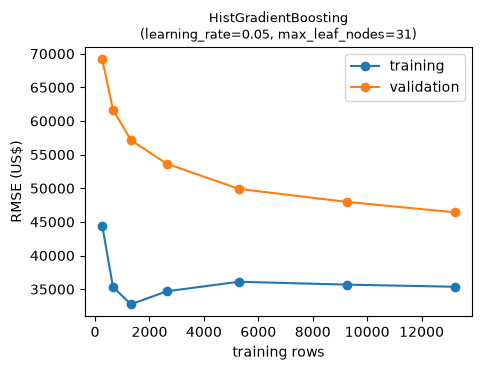

In [17]:
sizes, train, val = learning_curve(search.best_estimator_, X_train, y_train, train_sizes=fractions, cv=cv,
                                   scoring='neg_root_mean_squared_error', n_jobs=-1)
train, val = np.abs(train.mean(axis=1)), np.abs(val.mean(axis=1))
print('n     ' + ' '.join(f"{n:6d}" for n in sizes))
print('train ' + ' '.join(f"{v / 1000:6.1f}" for v in train))
print('valid ' + ' '.join(f"{v / 1000:6.1f}" for v in val))
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(sizes, train, 'o-', label='training')
ax.plot(sizes, val, 'o-', label='validation')
ax.set_title(describe(search.best_params_).replace('Regressor(', '\n('), fontsize=9)
ax.set_xlabel('training rows')
ax.set_ylabel('RMSE (US$)')
ax.legend()
plt.show()

**Conclusão.** Com todas as linhas, o vencedor erra US\$ 35,4 mil no treino e 46,4 mil na validação: uma distância de uns US\$ 11 mil, ainda do lado da variância (o linear tinha distância de US\$ 91). A validação continua caindo na borda direita (48,0 → 46,4 mil nas últimas 4.000 linhas), então mais distritos ainda ajudariam, de forma modesta. O treino alto nos tamanhos menores (44,5 mil com 264 linhas) vem do `early_stopping`, que para cedo quando há poucos dados.

### Sua vez — exercício 2 (avançado): aleatória em vez de grade

In [18]:
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV

param_dist = [
    {'model': [Ridge()], 'poly__degree': [1, 2, 3], 'model__alpha': loguniform(1, 1e4)},
    {'model': [KNeighborsRegressor()], **skip,
     'model__n_neighbors': randint(3, 60), 'model__weights': ['uniform', 'distance']},
    {'model': [DecisionTreeRegressor(random_state=42)], **skip, 'model__min_samples_leaf': randint(3, 60)},
    {'model': [RandomForestRegressor(n_estimators=100, random_state=42)], **skip,
     'model__max_features': [0.33, 1.0], 'model__min_samples_leaf': [1, 5]},
    {'model': [HistGradientBoostingRegressor(max_iter=500, early_stopping=True, random_state=42)], **skip,
     'model__learning_rate': loguniform(0.02, 0.3), 'model__max_leaf_nodes': [15, 31]},
]
rsearch = RandomizedSearchCV(pipe, param_dist, n_iter=30, cv=cv, scoring='neg_root_mean_squared_error',
                             n_jobs=-1, random_state=42).fit(X_train, y_train)
short = lambda p: describe({k: round(v, 3) if isinstance(v, float) else v for k, v in p.items()})

rres = pd.DataFrame(rsearch.cv_results_)
print('families drawn:', rres['params'].map(lambda p: type(p['model']).__name__).value_counts().to_dict())
for _, row in rres.sort_values('rank_test_score').head(5).iterrows():
    print(f"{row['rank_test_score']:2d}  {abs(row['mean_test_score']):6.0f} ± {row['std_test_score']:5.0f}"
          f"  {short(row['params'])}")

grid_best, grid_std = abs(search.best_score_), search.cv_results_['std_test_score'][search.best_index_]
running_best = np.minimum.accumulate(np.abs(rres['mean_test_score']))   # melhor até a i-ésima amostra
hit = np.argmax(running_best <= grid_best + grid_std)
print(f"grid winner {grid_best:.0f} ± {grid_std:.0f} · random best {running_best.iloc[-1]:.0f} "
      f"(difference {running_best.iloc[-1] - grid_best:.0f})")
print(f"random search within one std of the grid winner after {hit + 1} configurations "
      f"({(hit + 1) * cv.get_n_splits()} fits; the grid used {len(res) * cv.get_n_splits()})")

families drawn: {'RandomForestRegressor': 9, 'HistGradientBoostingRegressor': 9, 'DecisionTreeRegressor': 8, 'KNeighborsRegressor': 3, 'Ridge': 1}
 1   46694 ±  1165  HistGradientBoostingRegressor(learning_rate=0.057, max_leaf_nodes=31)
 2   46817 ±  1217  HistGradientBoostingRegressor(learning_rate=0.101, max_leaf_nodes=31)
 3   46866 ±  1062  HistGradientBoostingRegressor(learning_rate=0.068, max_leaf_nodes=31)
 4   46896 ±  1123  HistGradientBoostingRegressor(learning_rate=0.102, max_leaf_nodes=31)
 5   46917 ±   970  HistGradientBoostingRegressor(learning_rate=0.037, max_leaf_nodes=31)
grid winner 46644 ± 1311 · random best 46694 (difference 49)
random search within one std of the grid winner after 3 configurations (15 fits; the grid used 150)


**Conclusão.** Sim: a melhor das 30 configurações sorteadas é um boosting com `learning_rate≈0.057` e 31 folhas, 46.694 ± 1.165, só US\$ 49 acima do vencedor da grade (46.644 ± 1.311). Com `n_iter=30` o total de ajustes é o mesmo da grade (150), mas a busca já tinha uma configuração a menos de um desvio-padrão do vencedor na 3ª amostra (15 ajustes). Os cinco primeiros são todos boostings de 31 folhas com taxas de 0,037 a 0,102: um platô, que a amostragem contínua da taxa cobre melhor que os dois valores da grade.

### Sua vez — exercício 3 (avançado): avaliar o procedimento (CV aninhada)

In [19]:
from sklearn.model_selection import cross_val_score

nested = cross_val_score(search, X_train, y_train, cv=KFold(5, shuffle=True, random_state=1),
                         scoring='neg_root_mean_squared_error')   # 5 buscas completas: 750 ajustes
print('outer folds:', ' '.join(f"{abs(s):.0f}" for s in nested))
print(f"nested CV RMSE:      {abs(nested.mean()):.0f} ± {nested.std():.0f}")
print(f"search.best_score_:  {abs(search.best_score_):.0f}")
print(f"test RMSE (step 9):  {root_mean_squared_error(y_test, pred):.0f}")

outer folds: 48215 48945 45358 45605 46779
nested CV RMSE:      46980 ± 1410
search.best_score_:  46644
test RMSE (step 9):  46998


**Conclusão.** A CV aninhada dá US\$ 46.980 ± 1.410 (folds externos de 45.358 a 48.945), contra os 46.644 do `search.best_score_` e os 46.998 do teste. O `best_score_` é otimista em uns US\$ 336, a maldição do vencedor, pequena e dentro do desvio entre folds; a estimativa aninhada do procedimento inteiro (busca + escolha) fica a US\$ 18 do teste, sem precisar tocar nele.

### Sua vez — exercício 4 (avançado): a confiabilidade certa

In [20]:
# manter metade da vantagem: r = 8² / (8² + luck²) = 0.5  ->  luck² = 8²  ->  luck = 8
rng = np.random.default_rng(42)
n = 10_000
ability = rng.normal(70, 8, n)
print('luck sd      r   top 10% exam 1   exam 2   advantage kept')
for luck in [6, 8, 10]:
    exam1 = ability + rng.normal(0, luck, n)
    exam2 = ability + rng.normal(0, luck, n)
    top = exam1 >= np.quantile(exam1, 0.9)
    r = 8 ** 2 / (8 ** 2 + luck ** 2)
    kept = (exam2[top].mean() - exam2.mean()) / (exam1[top].mean() - exam1.mean())
    print(f"{luck:7d} {r:6.2f} {exam1[top].mean():16.1f} {exam2[top].mean():8.1f} {kept:16.2f}")

luck sd      r   top 10% exam 1   exam 2   advantage kept
      6   0.64             87.8     81.3             0.64
      8   0.50             89.8     80.0             0.51
     10   0.39             92.3     78.5             0.38


**Conclusão.** Manter metade da vantagem exige `r = 0.5`, ou seja, $8^2 / (8^2 + \sigma^2) = 0{,}5$, o que dá $\sigma = 8$: a sorte com o mesmo desvio-padrão da habilidade. Na simulação, os 10% de cima tiram 89,8 na primeira prova e 80,0 na segunda, mantendo 0,51 da vantagem; com sorte 6 mantêm 0,64 (r = 0,64) e com sorte 10, 0,38 (r = 0,39), batendo com a fórmula.

### Sua vez — exercício 5 (avançado): uma sétima família

In [21]:
from sklearn.datasets import fetch_openml, load_breast_cancer, make_moons
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

pipe_clf = Pipeline([('scale', StandardScaler()), ('model', LogisticRegression())])
grid_clf = [                                       # a grade da seção 9 ...
    {'model': [LogisticRegression(max_iter=5000)], 'model__C': np.logspace(-3, 3, 7)},
    {'model': [KNeighborsClassifier()], 'model__n_neighbors': [1, 3, 5, 9, 15, 25, 51]},
    {'model': [SVC()], 'model__C': [0.1, 1, 10, 100], 'model__gamma': ['scale', 0.01, 0.1]},
    {'model': [DecisionTreeClassifier(random_state=0)], 'scale': ['passthrough'],
     'model__max_depth': [1, 2, 3, 4, 6, 8, 12, None]},
    {'model': [RandomForestClassifier(n_estimators=200, random_state=0)], 'scale': ['passthrough'],
     'model__max_features': ['sqrt', 0.5], 'model__min_samples_leaf': [1, 5]},
    {'model': [HistGradientBoostingClassifier(random_state=0)], 'scale': ['passthrough'],
     'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [7, 31]},
    {'model': [SVC(kernel='linear')], 'model__C': np.logspace(-3, 1, 5)},   # ... mais a sétima família
]
search_clf = GridSearchCV(pipe_clf, grid_clf, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
                          scoring='accuracy', n_jobs=-1)
FAMILY = {'LogisticRegression': 'logistic', 'KNeighborsClassifier': 'k-NN', 'SVC': 'SVM',
          'DecisionTreeClassifier': 'tree', 'RandomForestClassifier': 'forest',
          'HistGradientBoostingClassifier': 'boosting'}


def family_of(model):
    name = FAMILY[type(model).__name__]
    return 'linear SVM' if name == 'SVM' and model.kernel == 'linear' else name


def best_per_family(search):
    res = pd.DataFrame(search.cv_results_)
    res['family'] = [family_of(p['model']) for p in res['params']]
    best = res.loc[res.groupby('family')['mean_test_score'].idxmax()]
    best['setting'] = [', '.join(f"{k.split('__')[1]}={v}" for k, v in p.items() if '__' in k)
                       for p in best['params']]
    return best.set_index('family')[['mean_test_score', 'std_test_score', 'setting']]


def rule_data(n=500, p=20, seed=0):
    r = np.random.default_rng(seed)
    X = r.uniform(0, 1, (n, p))
    y = (((X[:, 0] > 0.6) & (X[:, 1] > 0.3)) | (X[:, 0] < 0.2)).astype(int)
    flip = r.random(n) < 0.05
    return X, np.where(flip, 1 - y, y)


def linear_data(n=200, p=40, seed=0):
    r = np.random.default_rng(seed)
    X = r.normal(size=(n, p))
    return X, (X @ r.normal(size=p) + r.normal(0, 2, n) > 0).astype(int)


ion = fetch_openml(data_id=59, as_frame=True)
credit = fetch_openml(data_id=31, as_frame=True)
datasets = {
    'ionosphere (real)': (ion.data, (ion.target == 'g').astype(int)),
    'breast cancer (real)': load_breast_cancer(return_X_y=True),
    'credit-g (real)': (pd.get_dummies(credit.data, dtype=float), (credit.target == 'good').astype(int)),
    'linear, 40-d': linear_data(),
    'two moons': make_moons(n_samples=400, noise=0.3, random_state=0),
    'axis-aligned rule': rule_data(),
}
table = {}
for name, (Xd, yd) in datasets.items():
    best = best_per_family(search_clf.fit(Xd, yd))
    scores = best['mean_test_score']
    winner = scores.idxmax()
    lin, log = best.loc['linear SVM'], best.loc['logistic']
    table[name] = {**{fam: f"{acc:.3f}" for fam, acc in scores.items()}, 'winner': winner,
                   'its std': f"{best.loc[winner, 'std_test_score']:.3f}",
                   'linSVM-log': f"{lin['mean_test_score'] - log['mean_test_score']:+.3f}",
                   'tie?': abs(lin['mean_test_score'] - log['mean_test_score'])
                           < max(lin['std_test_score'], log['std_test_score']),
                   'linear SVM C': lin['setting']}
cols = ['logistic', 'linear SVM', 'k-NN', 'SVM', 'tree', 'forest', 'boosting', 'winner', 'its std',
        'linSVM-log', 'tie?', 'linear SVM C']
print(pd.DataFrame(table).T[cols].to_string())

                     logistic linear SVM   k-NN    SVM   tree forest boosting      winner its std linSVM-log  tie? linear SVM C
ionosphere (real)       0.883      0.886  0.866  0.946  0.897  0.943    0.940         SVM   0.037     +0.003  True        C=0.1
breast cancer (real)    0.979      0.977  0.965  0.979  0.930  0.967    0.972    logistic   0.014     -0.002  True        C=0.1
credit-g (real)         0.761      0.744  0.735  0.760  0.719  0.762    0.771    boosting   0.010     -0.017  True        C=0.1
linear, 40-d            0.820      0.830  0.710  0.805  0.725  0.740    0.720  linear SVM   0.068     +0.010  True        C=0.1
two moons               0.853      0.855  0.900  0.895  0.887  0.893    0.895        k-NN   0.036     +0.003  True       C=10.0
axis-aligned rule       0.640      0.644  0.636  0.686  0.938  0.948    0.944      forest   0.025     +0.004  True        C=0.1


**Conclusão.** A SVM linear empata com a regressão logística nos seis conjuntos (diferenças de no máximo 0,017, abaixo do desvio-padrão entre folds): 0,886 contra 0,883 em ionosphere, 0,977 contra 0,979 em breast cancer, 0,830 contra 0,820 no linear 40-d (onde passa a ser a vencedora), 0,855 contra 0,853 nas duas luas e 0,644 contra 0,640 na regra alinhada aos eixos; a maior diferença é em credit-g (0,744 contra 0,761). Era o esperado: as duas são classificadores lineares regularizados por `C`, com o mesmo viés indutivo (um hiperplano) e só a função de perda diferente (hinge contra logística), então ganham e perdem nos mesmos lugares.